
# Modules
To enable autoreloading of all modules, it is necessary to install IPython by executing the following command: **pip install ipython**

Example of module importation:
```python
from Modules import data_manipulation_module as dmm
```

| Modul names                   | Description                                             |
|-------------------------------|---------------------------------------------------------|
| data_manipulation_module      | Functions for data manipulation                         |
| nts_classification_module     | Functions for non-time series classification algorithms |
| ts_classification_module      | Functions for time series classification algorithms     |
| validation_and_results_module | Functions for validation and results                    |
| param_tuning_module           | Functions for parameter tuning                          |
| dim_reduction_module          | Functions for dimensionality reduction                  |
| plots_module                  | Functions for plotting                                  |

In [4]:
#autoreload all the modules (no need to rerun the module importation statement to implement the changes)
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


---
## 1. Codes from the introduction Notebook
### 1.1. Data loading

In [2]:
import glob
import pandas as pd

#beacuse of k-nn
from warnings import simplefilter
simplefilter(action='ignore', category = FutureWarning)

#Numpy version check
import numpy as np
np.__version__
#delete the comment before pip if the version is not 1.21.4
#pip install --upgrade numpy==1.21.4 --user

'1.21.4'

In [5]:
from Modules import data_manipulation_module as dmm 

In [6]:
#Saving the files names
KT_csv_files = glob.glob('/tf/notebooks/DatasCSV/KT/*.csv')
NP_csv_files = glob.glob('/tf/notebooks/DatasCSV/NP/*.csv')
SU_csv_files = glob.glob('/tf/notebooks/DatasCSV/SU/*.csv')

KT_csv_files = sorted(KT_csv_files)
NP_csv_files = sorted(NP_csv_files)
SU_csv_files = sorted(SU_csv_files)

In [7]:
#Loading_datafiles, separator, col_names)
NP_df_list = dmm.Loading_data(NP_csv_files, ";", None)
KT_df_list = dmm.Loading_data(KT_csv_files, ";", None)
SU_df_list = dmm.Loading_data(SU_csv_files, ";", None)

In [8]:
#Target vairable files loading
NP_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Needle_Passing.txt', " ", None)
KT_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Knot_Tying.txt', " ", None)
SU_class = dmm.Loading_data('/tf/notebooks/Class/meta_file_Suturing.txt', " ", None)

In [9]:
#Selecting the GRS as the target variable (binary classification)
#If the GRS score is below 16 (with a maximum possible score of 30), the participant is classified as 0, indicating the novice class
#Conversely, a score of 16 or higher results in a classification of 1, indicating the expert class
NP_class_binary = NP_class.copy()
KT_class_binary = KT_class.copy()
SU_class_binary = SU_class.copy()

NP_class_binary["GRS"] = np.where(NP_class["GRS"] < 16, 0, 1)
KT_class_binary["GRS"] = np.where(KT_class["GRS"] < 16, 0, 1)
SU_class_binary["GRS"] = np.where(SU_class["GRS"] < 16, 0, 1)

In [10]:
#Selecting the GRS as the target variable (multiclass classification)
#Multi_class_target_variable(df_class_value, class_tresholds)
    #class_tresholds: [11, 21, 31]
        #GRS < 11 then 0, < 21  then 1, < 31 then 2
        
NP_class_multi = NP_class.copy()
KT_class_multi = KT_class.copy()
SU_class_multi = SU_class.copy()

NP_class_multi["GRS"] = NP_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
KT_class_multi["GRS"] = KT_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))
SU_class_multi["GRS"] = SU_class_multi["GRS"].apply(lambda x: dmm.Multi_class_target_variable(x, [11, 21, 31]))

---
## 2. Gestures
### 2.1. Data Loading

In [11]:
NP_gesture_files = glob.glob('/tf/notebooks/Gestures/NP/*.csv')
KT_gesture_files = glob.glob('/tf/notebooks/Gestures/KT/*.csv')
SU_gesture_files = glob.glob('/tf/notebooks/Gestures/SU/*.csv')

NP_gesture_files = sorted(NP_gesture_files)
KT_gesture_files = sorted(KT_gesture_files)
SU_gesture_files = sorted(SU_gesture_files)

In [12]:
NP_gesture_df_list = dmm.Loading_data(NP_gesture_files, ";", None)
KT_gesture_df_list = dmm.Loading_data(KT_gesture_files, ";", None)
SU_gesture_df_list = dmm.Loading_data(SU_gesture_files, ";", None)

In [13]:
NP_gesture_df_list[0]

,Start_frame,End_frame,Gesture
0,166,586,G1
1,587,794,G2
2,795,821,G3
3,822,962,G6
4,963,1113,G4
5,1114,1448,G2
6,1449,1492,G3
7,1493,1631,G6
8,1632,1775,G4
9,1776,2184,G2


### 2.2. Dataset division by gestures

In [14]:
#Needle-passing = ['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G8','G11']
#Knot-tying = ['G1', 'G11', 'G12', 'G13', 'G14', 'G15']
#Suturing = ['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G8', 'G9', 'G10', 'G11']

Needle_Passing_gestures = [1, 2, 3, 4, 5, 6, 8, 11]
Knot_Tying_gestures = [1 , 11 , 12 , 13 , 14 , 15]
Suturing_gestures = [1, 2, 3, 4, 5, 6, 8, 9, 10, 11]

number_of_gestures = 15
feature_names = NP_df_list[0].columns

In [15]:
NP_df_list[0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.118529,-0.015860,0.367277,0.482652,-0.326916,-0.812538,0.642312,0.762788,0.074571,0.594823,...,-0.583559,0.578939,0.569462,-0.013975,-0.002687,0.006508,-0.021289,-0.230186,0.452584,-1.198475
1,0.117837,-0.016283,0.367878,0.470070,-0.331100,-0.818200,0.649242,0.757665,0.066332,0.597381,...,-0.585849,0.583027,0.562902,-0.006929,-0.003082,0.006237,-0.019702,-0.142757,0.343896,-1.202884
2,0.117591,-0.016579,0.368282,0.464992,-0.333945,-0.819944,0.652489,0.755208,0.062384,0.597824,...,-0.586203,0.584588,0.560911,-0.007013,-0.007571,0.011385,-0.058685,-0.138019,0.321906,-1.201741
3,0.117164,-0.017204,0.369130,0.457999,-0.337982,-0.822223,0.657503,0.751245,0.057376,0.597736,...,-0.586036,0.587470,0.558068,-0.000156,-0.008891,0.010383,-0.064197,-0.068266,0.171226,-1.198312
4,0.116830,-0.017850,0.369779,0.457318,-0.342555,-0.820707,0.656666,0.752381,0.051810,0.599175,...,-0.587479,0.583116,0.561108,-0.000627,-0.011057,0.008655,-0.058588,0.077483,-0.011222,-1.195536
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3433,0.142431,-0.019635,0.426738,0.857629,-0.247396,-0.450902,0.299046,0.953128,0.045724,0.417392,...,-0.417144,0.192595,0.888198,-0.000274,-0.002466,-0.001380,-2.250799,1.036829,4.962650,-0.540414
3434,0.142378,-0.019676,0.426621,0.861480,-0.264215,-0.433691,0.312973,0.948748,0.043565,0.398884,...,-0.397702,0.195262,0.896495,-0.000363,0.001951,-0.006721,0.063972,0.508576,-0.221638,-0.391330
3435,0.142191,-0.019512,0.425955,0.863868,-0.297715,-0.406378,0.342397,0.938687,0.040040,0.368470,...,-0.365923,0.194084,0.910181,-0.000650,-0.000191,-0.007957,0.166514,0.675894,-0.078584,-0.081241
3436,0.142137,-0.019330,0.425178,0.871721,-0.299333,-0.388004,0.338906,0.940116,0.036006,0.352910,...,-0.350691,0.183105,0.918415,-0.000539,0.005146,-0.012726,0.200262,0.397835,-0.071289,0.174962


In [16]:
#Gestures_data_splitting(number_of_gestures, feature_names, gestures, gesture_df_list, df_list)  
NP_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Needle_Passing_gestures, NP_gesture_df_list, NP_df_list)
KT_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Knot_Tying_gestures, KT_gesture_df_list, KT_df_list)
SU_gestures = dmm.Gestures_data_splitting(number_of_gestures, feature_names, Suturing_gestures, SU_gesture_df_list, SU_df_list)

In [17]:
#NP: First trial, G1 gesture
NP_gestures[0][0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
165,0.122440,-0.009416,0.369173,0.503405,-0.674849,-0.539635,0.838535,0.532201,0.116587,0.207896,...,-0.197533,0.526692,0.826786,0.008689,0.000199,0.017226,-0.067299,-0.015465,0.040622,-1.199618
166,0.123061,-0.009454,0.370664,0.498900,-0.676487,-0.541765,0.841600,0.527386,0.116381,0.206375,...,-0.196030,0.529450,0.825381,0.008540,-0.004558,0.022066,-0.101243,0.003098,0.025459,-1.203374
167,0.123851,-0.009542,0.372253,0.494349,-0.679900,-0.541665,0.844835,0.522464,0.115140,0.204108,...,-0.193880,0.529689,0.825735,0.009125,0.002773,0.019010,-0.075355,-0.036226,0.069847,-1.203700
168,0.124222,-0.009525,0.373064,0.492112,-0.684211,-0.538263,0.846576,0.520179,0.112669,0.202299,...,-0.192257,0.526462,0.828175,0.009140,0.002962,0.019103,0.025731,0.189645,0.168133,-1.203537
169,0.124820,-0.009403,0.374698,0.487090,-0.698044,-0.524903,0.850600,0.515449,0.103752,0.197538,...,-0.188041,0.513254,0.837382,0.002181,-0.001068,0.024481,0.273337,0.846639,0.382412,-1.205660
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581,0.124760,0.001993,0.340078,0.403285,0.389159,-0.828228,-0.050361,0.913147,0.404474,0.913200,...,-0.910993,0.147282,0.385226,-0.000404,-0.006240,0.003559,-0.035309,0.016744,-0.018136,-0.272454
582,0.124189,0.001956,0.340122,0.399596,0.383776,-0.832517,-0.048589,0.915752,0.398761,0.914920,...,-0.912750,0.144741,0.382015,-0.013905,0.000905,0.000652,-0.002749,0.033245,-0.065008,-0.271964
583,0.123843,0.001944,0.340163,0.396867,0.379714,-0.835679,-0.047219,0.917674,0.394483,0.916181,...,-0.914075,0.142932,0.379520,-0.014100,-0.004229,0.005149,-0.037357,0.047086,-0.078607,-0.268862
584,0.123098,0.001920,0.340243,0.388461,0.366819,-0.845332,-0.042755,0.923550,0.381050,0.920003,...,-0.917786,0.137994,0.372322,-0.007308,-0.005665,0.003999,0.306264,-1.551509,2.385201,-0.261024


In [19]:
#Gestures_ApEn_transform_target_append(number_of_gestures, df_gestures, feature_names, df_classes, classes_target_idx)
NP_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, NP_gestures, feature_names, NP_class_binary, 2)
KT_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, KT_gestures, feature_names, KT_class_binary, 2)
SU_gestures_ApEn_binary = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, SU_gestures, feature_names, SU_class_binary, 2)

In [20]:
NP_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, NP_gestures, feature_names, NP_class_multi, 2)
KT_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, KT_gestures, feature_names, KT_class_multi, 2)
SU_gestures_ApEn_multi = dmm.Gestures_ApEn_transform_target_append(number_of_gestures, SU_gestures, feature_names, SU_class_multi, 2)

In [21]:
#G1 gesture
NP_gestures_ApEn_binary[0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV,GRS
0,0.082200,0.083706,0.073556,0.111288,0.033006,0.060569,0.027569,0.034601,0.066871,0.038984,...,0.074964,0.045755,0.458528,0.511612,0.405717,0.462408,0.578762,0.625891,0.054807,0
1,0.049700,0.175427,0.104603,0.055948,0.198399,0.042356,0.080422,0.080677,0.143006,0.227344,...,0.047121,0.040153,0.436184,0.510720,0.379122,0.265976,0.323464,0.276111,0.048914,0
2,0.330320,0.049043,0.065385,0.172673,0.201934,0.050017,0.202567,0.242964,0.049325,0.263389,...,0.204035,0.145584,0.251641,0.611000,0.467216,0.229201,0.537279,0.540783,0.017925,0
3,0.063245,0.271783,0.152117,0.107990,0.255323,0.150461,0.085459,0.114881,0.147825,0.171310,...,0.131797,0.249664,0.306397,0.526229,0.377954,0.372135,0.577747,0.546099,0.109421,1
4,0.236020,0.245251,0.355127,0.567852,0.435929,0.532521,0.502741,0.469652,0.364230,0.427901,...,0.372701,0.504750,0.416744,0.388331,0.388331,0.129488,0.129488,0.129488,0.257043,0
5,0.020010,0.155349,0.083370,0.200221,0.140505,0.134350,0.143450,0.143926,0.014416,0.106543,...,0.079019,0.076995,0.245879,0.473437,0.278212,0.150530,0.327341,0.408881,0.048704,0
6,0.099502,0.089139,0.174860,0.268406,0.273380,0.065079,0.248482,0.265485,0.098109,0.137993,...,0.298937,0.155947,0.333795,0.455104,0.251630,0.084803,0.342299,0.396339,0.192497,0
7,0.123830,0.051828,0.091080,0.495714,0.222219,0.008155,0.302132,0.202577,0.012078,0.067115,...,0.119773,0.012882,0.204249,0.239358,0.476829,0.172943,0.425240,0.437234,0.071614,0
8,0.106091,0.287209,0.225013,0.105221,0.099246,0.025512,0.113488,0.107079,0.050036,0.121229,...,0.168566,0.045127,0.375806,0.791004,0.819884,0.138817,0.365338,0.150325,0.176151,0
9,0.035428,0.081504,0.068645,0.028685,0.089269,0.067143,0.063885,0.072613,0.048479,0.094271,...,0.058552,0.044975,0.482900,0.407107,0.402105,0.220003,0.425816,0.480213,0.182572,0


In [22]:
number_of_gestures_x_axis = [f"G{i}" for i in range(1, number_of_gestures+1)]
NP_gestures_ApEn_lengths = [len(df) for df in NP_gestures_ApEn_binary]
KT_gestures_ApEn_lengths = [len(df) for df in KT_gestures_ApEn_binary]
SU_gestures_ApEn_lengths = [len(df) for df in SU_gestures_ApEn_binary]

In [54]:
%set_env TF_ENABLE_ONEDNN_OPTS=0
from Modules import plots_module as pm

env: TF_ENABLE_ONEDNN_OPTS=0


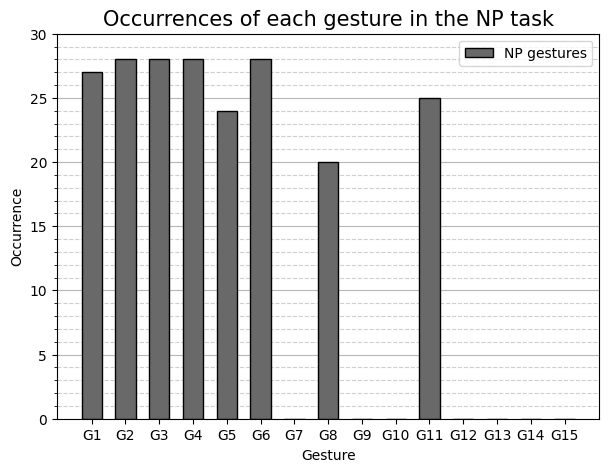

In [26]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_gestures_ApEn_lengths], "Occurrences of each gesture in the NP task", number_of_gestures_x_axis, "Gesture", \
            np.arange(0, np.max([NP_gestures_ApEn_lengths])+4, 5), "Occurrence", ["NP gestures"], ["dimgray"], 0.6, (7, 5))

In [27]:
#Splitting the data into features and target variable (gestures)
#Gestures_features_target(task_gestures, gestures_idxs, minimum_rows)
print("Binary:")
NP_gestures_X_ApEn, NP_gestures_Y_ApEn_binary, Needle_Passing_gestures_binary = dmm.Gestures_features_target(NP_gestures_ApEn_binary, Needle_Passing_gestures, 4)
KT_gestures_X_ApEn, KT_gestures_Y_ApEn_binary, Knot_Tying_gestures_binary = dmm.Gestures_features_target(KT_gestures_ApEn_binary, Knot_Tying_gestures, 4)
SU_gestures_X_ApEn, SU_gestures_Y_ApEn_binary, Suturing_gestures_binary = dmm.Gestures_features_target(SU_gestures_ApEn_binary, Suturing_gestures, 4)

print("\nMulti:")
NP_gestures_X_ApEn, NP_gestures_Y_ApEn_multi, Needle_Passing_gestures_multi = dmm.Gestures_features_target(NP_gestures_ApEn_multi, Needle_Passing_gestures, 4)
KT_gestures_X_ApEn, KT_gestures_Y_ApEn_multi, Knot_Tying_gestures_multi = dmm.Gestures_features_target(KT_gestures_ApEn_multi, Knot_Tying_gestures, 4)
SU_gestures_X_ApEn, SU_gestures_Y_ApEn_multi, Suturing_gestures_multi = dmm.Gestures_features_target(SU_gestures_ApEn_multi, Suturing_gestures, 4)

Binary:
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 11]
Final gestures for the task: [1, 11, 12, 13, 14, 15]
There is not enough data in the G10 gesture
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 9, 11]

Multi:
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 11]
Final gestures for the task: [1, 11, 12, 13, 14, 15]
There is not enough data in the G10 gesture
Final gestures for the task: [1, 2, 3, 4, 5, 6, 8, 9, 11]


### 2.3. Train-test dataset

In [28]:
#Splitting the data into training and testing datasets (gestures)   
#Gestures_train_test(X, Y, t_size)
NP_gestures_X_train_ApEn, NP_gestures_Y_train_ApEn_binary, NP_gestures_X_test_ApEn, NP_gestures_Y_test_ApEn_binary = dmm.Gestures_train_test(NP_gestures_X_ApEn, NP_gestures_Y_ApEn_binary, 0.3)
KT_gestures_X_train_ApEn, KT_gestures_Y_train_ApEn_binary, KT_gestures_X_test_ApEn, KT_gestures_Y_test_ApEn_binary = dmm.Gestures_train_test(KT_gestures_X_ApEn, KT_gestures_Y_ApEn_binary, 0.3)
SU_gestures_X_train_ApEn, SU_gestures_Y_train_ApEn_binary, SU_gestures_X_test_ApEn, SU_gestures_Y_test_ApEn_binary = dmm.Gestures_train_test(SU_gestures_X_ApEn, SU_gestures_Y_ApEn_binary, 0.3)

In [29]:
#Multiclass version
NP_gestures_X_train_ApEn, NP_gestures_Y_train_ApEn_multi, NP_gestures_X_test_ApEn, NP_gestures_Y_test_ApEn_multi = dmm.Gestures_train_test(NP_gestures_X_ApEn, NP_gestures_Y_ApEn_multi, 0.3)
KT_gestures_X_train_ApEn, KT_gestures_Y_train_ApEn_multi, KT_gestures_X_test_ApEn, KT_gestures_Y_test_ApEn_multi = dmm.Gestures_train_test(KT_gestures_X_ApEn, KT_gestures_Y_ApEn_multi, 0.3)
SU_gestures_X_train_ApEn, SU_gestures_Y_train_ApEn_multi, SU_gestures_X_test_ApEn, SU_gestures_Y_test_ApEn_multi = dmm.Gestures_train_test(SU_gestures_X_ApEn, SU_gestures_Y_ApEn_multi, 0.3)

### 2.4. Standardization

In [30]:
#Standardizing the features
#Gestures_standardization(gestures_X_train, gesture_X_test)
NP_gestures_standardized_X_train_ApEn, NP_gestures_standardized_X_test_ApEn = dmm.Gestures_standardization(NP_gestures_X_train_ApEn, NP_gestures_X_test_ApEn)
KT_gestures_standardized_X_train_ApEn, KT_gestures_standardized_X_test_ApEn = dmm.Gestures_standardization(KT_gestures_X_train_ApEn, KT_gestures_X_test_ApEn)
SU_gestures_standardized_X_train_ApEn, SU_gestures_standardized_X_test_ApEn = dmm.Gestures_standardization(SU_gestures_X_train_ApEn, SU_gestures_X_test_ApEn)

---
## 3. Gestures: Non-time series classifiers

In [49]:
from Modules import nts_classification_algorithms_module as nts_cam
from Modules import validation_and_results_module as vrm

## 3.1. Decision Tree
| Parameter names | Values                           |
|-----------------|----------------------------------|
| criterion       | “gini”, “entropy”, “log_loss”    |
| splitter        | “best”, “random”                 |
| max_depth       | None, int                        |
| max_features    | None, int, float, “sqrt”, “log2” |

### 3.1.1. Model creation and traning-testing

In [32]:
#Decision_tree(criterion, splitter, max_depth, max_features)
DT_model_ApEn_binary = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_model_ApEn_multi = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_standardized_model_ApEn_binary = nts_cam.Decision_tree("entropy", "random", 5, 5)
DT_standardized_model_ApEn_multi = nts_cam.Decision_tree("entropy", "random", 5, 5)

DT_model_ApEn_binary

DecisionTreeClassifier(criterion='entropy', max_depth=5, max_features=5,
                       random_state=0, splitter='random')

In [33]:
#One gesture
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(DT_model_ApEn_binary, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

Actual classes: [0 0 0 1 0 0 0 0 1], Predicted classes: [0 0 1 0 0 1 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.57      0.67         7
           1       0.25      0.50      0.33         2

    accuracy                           0.56         9
   macro avg       0.53      0.54      0.50         9
weighted avg       0.68      0.56      0.59         9



In [34]:
#All gestures
for i in range(len(NP_gestures_X_ApEn)):
    print(f"\nGesture: {Needle_Passing_gestures_binary[i]}")
    vrm.Model_classification_report(DT_model_ApEn_binary, NP_gestures_X_train_ApEn[i], NP_gestures_X_test_ApEn[i], NP_gestures_Y_train_ApEn_binary[i], NP_gestures_Y_test_ApEn_binary[i])


Gesture: 1
Actual classes: [0 0 0 1 0 0 0 0 1], Predicted classes: [0 0 1 0 0 1 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.57      0.67         7
           1       0.25      0.50      0.33         2

    accuracy                           0.56         9
   macro avg       0.53      0.54      0.50         9
weighted avg       0.68      0.56      0.59         9


Gesture: 2
Actual classes: [0 1 0 1 0 0 0 0 1], Predicted classes: [0 0 0 0 0 0 0 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.75      1.00      0.86         6
           1       1.00      0.33      0.50         3

    accuracy                           0.78         9
   macro avg       0.88      0.67      0.68         9
weighted avg       0.83      0.78

### 3.1.2. Results checking

In [35]:
from sklearn.tree import DecisionTreeClassifier

In [36]:
model = DecisionTreeClassifier(criterion="entropy", max_depth=5, max_features=5, random_state=0, splitter="random")
model.fit(NP_gestures_X_train_ApEn[0], NP_gestures_Y_train_ApEn_binary[0])
model.score(NP_gestures_X_test_ApEn[0], NP_gestures_Y_test_ApEn_binary[0])

0.5555555555555556

### 3.1.3. Cross-validation

In [37]:
#One gesture
model_cv = DecisionTreeClassifier(criterion="entropy", max_depth=5, max_features=5, random_state=0, splitter="random")

print(f"Gesture: {Needle_Passing_gestures_binary[0]}")
print(vrm.Cross_validation(model_cv, NP_gestures_X_train_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], 3))

Gesture: 1
0.6111111111111112


In [38]:
#All gestures
NP_DT_gestures_ApEn_acc_binary = []

for i in range(len(NP_gestures_X_train_ApEn)):
    print(f"Gesture: {Needle_Passing_gestures_binary[i]}")
    NP_DT_gestures_ApEn_acc_binary.append(vrm.Cross_validation(model_cv, NP_gestures_X_train_ApEn[i], NP_gestures_Y_train_ApEn_binary[i], 3))
    print(f"{NP_DT_gestures_ApEn_acc_binary[i]}\n")

Gesture: 1
0.6111111111111112

Gesture: 2
0.5158730158730159

Gesture: 3
0.6825396825396824

Gesture: 4
0.6190476190476191

Gesture: 5
0.8666666666666667

Gesture: 6
0.5793650793650793

Gesture: 8
0.5833333333333334

Gesture: 11
0.5333333333333333



### 3.1.4. DT visualization

In [39]:
Needle_Passing_x_axis = [f"G{i}" for i in Needle_Passing_gestures_binary]
Needle_Passing_x_axis

['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G8', 'G11']

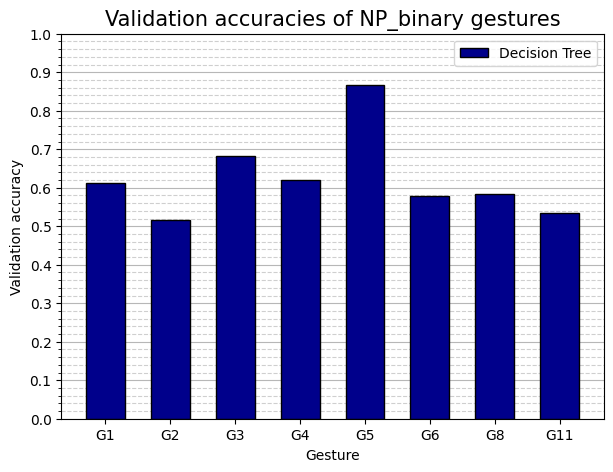

In [40]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_DT_gestures_ApEn_acc_binary], "Validation accuracies of NP_binary gestures", Needle_Passing_x_axis, "Gesture", \
            np.arange(0, 1.1, 0.1), "Validation accuracy", ["Decision Tree"], ["darkblue"], 0.6, (7, 5))

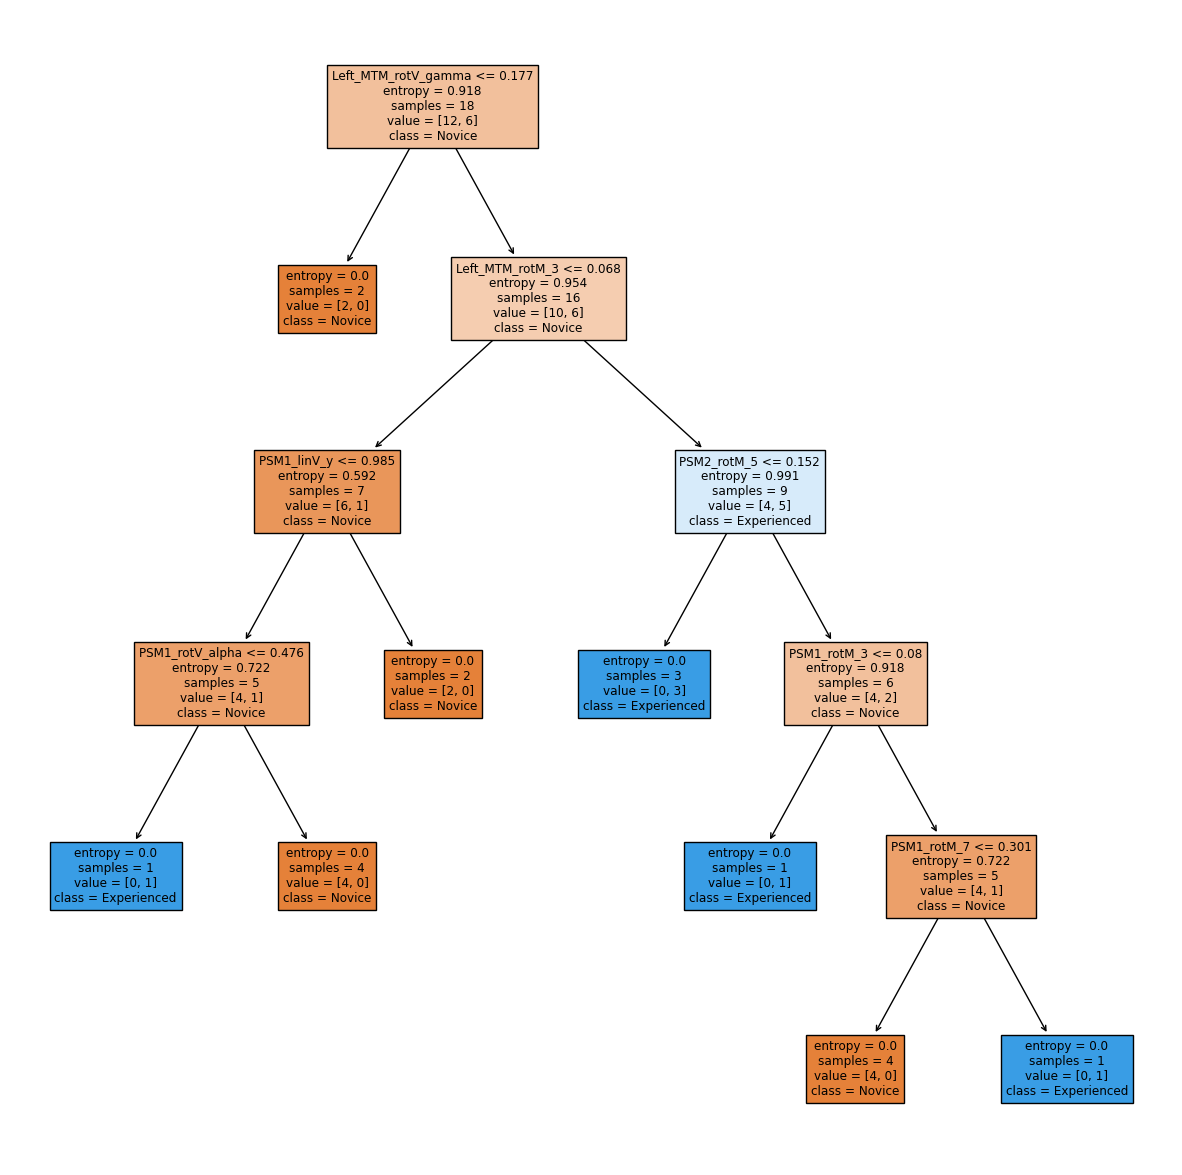

In [41]:
#Decision_tree_visualization(class_names, model, feature_names, fig_size)
    #class names should be in ascending order: 0,1,2,3...
    #0-Novice, 1-Experienced --> Novice, Experienced
pm.Decision_tree_visualization(["Novice", "Experienced"], model, feature_names, (15,15))

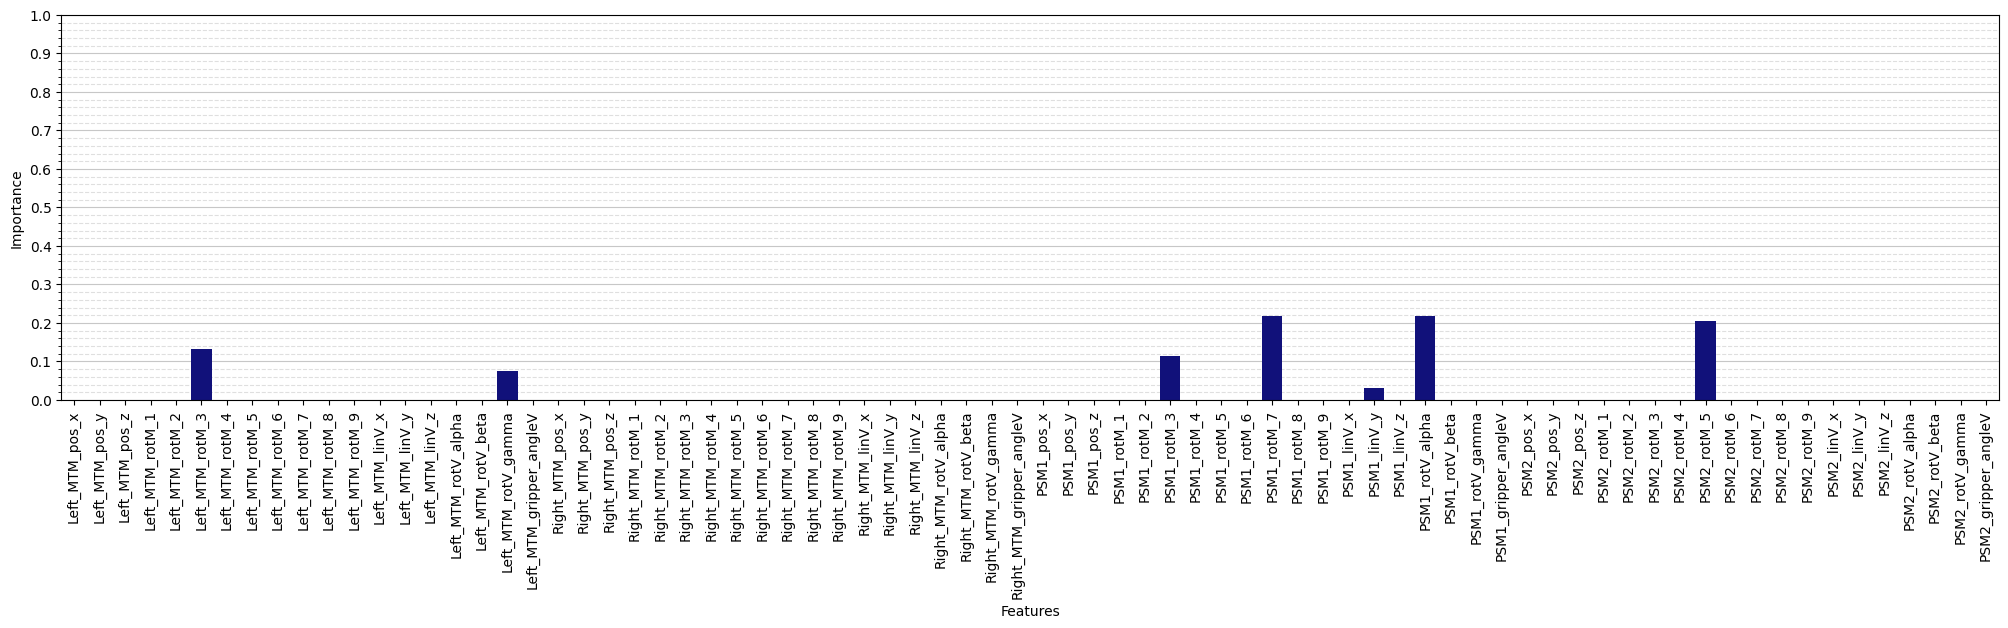

In [42]:
#Decision_tree_feature_importance(model, features, bar_color, fig_size, sort, only_not_null, vertical)
pm.Decision_tree_feature_importance(model, feature_names, "darkblue", (25,5), False, False, True)

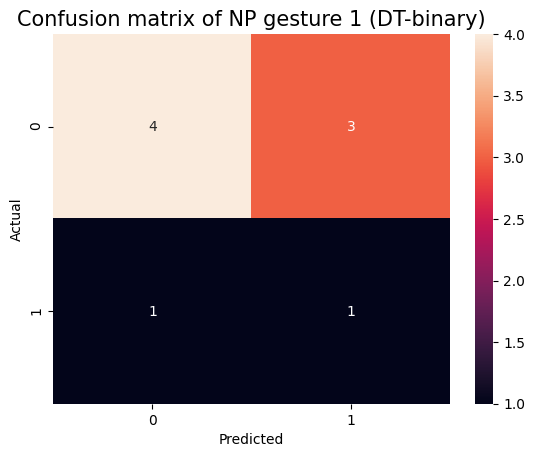

In [43]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of NP gesture 1 (DT-binary)", model, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

## 3.2. Logistic Regression
| Parameter names | Values                                           |
|-----------------|--------------------------------------------------|
| penalty         | “l1”, “l2”, None                                 |
| C               | float                                            |
| solver          | “lbfgs”, “liblinear”, “newton-cg”, “sag”, “saga” |
| max_iter        | int                                              |
| binary_class    | True, False                                      |

| Solver      | Penalty          |
|-------------|------------------|
| “lbfgs”     | “l2”, None       |
| “liblinear” | “l1”, “l2”       |
| “newton-cg” | “l2”, None       |
| “sag”       | “l2”, None       |
| “saga”      | “l1”, “l2”, None |

### 3.2.1. Model creation and traning-testing

In [44]:
#Logistic_regression(penalty, C, solver, max_iter, binary_class)
    #binary_class: True, False
        #True: Binary classification
        #False: Multi   
LogR_model_ApEn_binary = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, True)
LogR_model_ApEn_multi = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, False)
LogR_standardized_model_ApEn_binary = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, True)
LogR_standardized_model_ApEn_multi = nts_cam.Logistic_regression("l2", 2.0, "newton-cg", 5000, False)

LogR_model_ApEn_binary

LogisticRegression(C=2.0, max_iter=5000, random_state=0, solver='newton-cg')

In [45]:
#One gesture
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(LogR_model_ApEn_binary, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

Actual classes: [0 0 0 1 0 0 0 0 1], Predicted classes: [0 0 0 0 0 0 0 0 0]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.78      1.00      0.88         7
           1       0.00      0.00      0.00         2

    accuracy                           0.78         9
   macro avg       0.39      0.50      0.44         9
weighted avg       0.60      0.78      0.68         9



### 3.2.2. Results checking

In [46]:
from sklearn.linear_model import LogisticRegression

In [47]:
#Checking the results
model = LogisticRegression(random_state = 0, penalty = "l2", C = 2.0, solver = "newton-cg", max_iter = 5000)
model.fit(NP_gestures_X_train_ApEn[0], NP_gestures_Y_train_ApEn_binary[0])
model.score(NP_gestures_X_test_ApEn[0], NP_gestures_Y_test_ApEn_binary[0])

0.7777777777777778

### 3.2.3. Cross-validation

In [48]:
#All gestures
model_cv = LogisticRegression(random_state = 0, penalty = "l2", C = 2.0, solver = "newton-cg", max_iter = 5000)
NP_LR_gestures_ApEn_acc_binary = []

for i in range(len(NP_gestures_X_train_ApEn)):
    print(f"Gesture: {Needle_Passing_gestures_binary[i]}")
    NP_LR_gestures_ApEn_acc_binary.append(vrm.Cross_validation(model_cv, NP_gestures_X_train_ApEn[i], NP_gestures_Y_train_ApEn_binary[i], 3))
    print(f"{NP_LR_gestures_ApEn_acc_binary[i]}\n")

Gesture: 1
0.5555555555555555

Gesture: 2
0.6825396825396824

Gesture: 3
0.626984126984127

Gesture: 4
0.6825396825396824

Gesture: 5
0.7555555555555555

Gesture: 6
0.7380952380952381

Gesture: 8
0.7166666666666667

Gesture: 11
0.7111111111111111



### 3.2.4. LR visualization

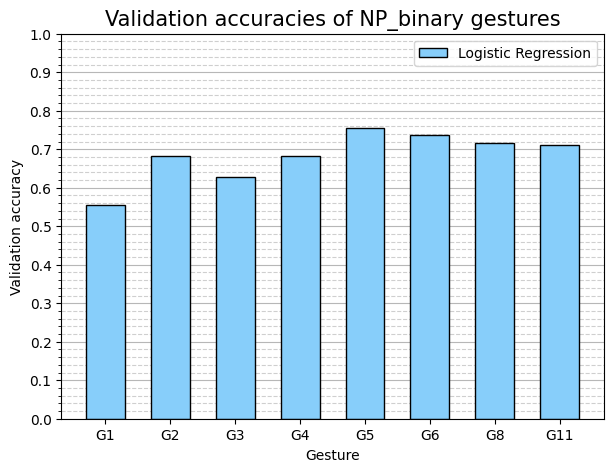

In [49]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_LR_gestures_ApEn_acc_binary], "Validation accuracies of NP_binary gestures", Needle_Passing_x_axis, "Gesture", \
            np.arange(0, 1.1, 0.1), "Validation accuracy", ["Logistic Regression"], ["lightskyblue"], 0.6, (7, 5))

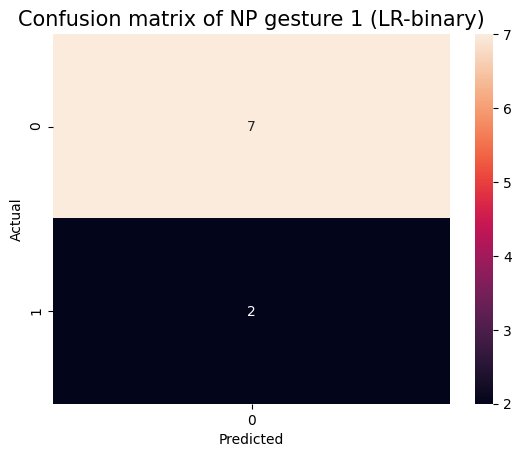

In [50]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of NP gesture 1 (LR-binary)", model, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

## 3.3. K-NN
| Parameter names | Values                                |
|-----------------|---------------------------------------|
| n_neighbors     | int                                   |
| weights         | “uniform”, “distance”                 |
| metric          | “euclidean”, “manhattan”, “minkowski” |

### 3.3.1. Model creation and traning-testing

In [51]:
#kNN(n_neighbors, weights, metric)
kNN_model_ApEn_binary = nts_cam.kNN(1, "distance", "euclidean")
kNN_model_ApEn_multi = nts_cam.kNN(1, "distance", "euclidean")
kNN_standardized_model_ApEn_binary = nts_cam.kNN(1, "distance", "euclidean")
kNN_standardized_model_ApEn_multi = nts_cam.kNN(1, "distance", "euclidean")

kNN_model_ApEn_binary

KNeighborsClassifier(metric='euclidean', n_neighbors=1, weights='distance')

In [52]:
#One gesture
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(kNN_model_ApEn_binary, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

Actual classes: [0 0 0 1 0 0 0 0 1], Predicted classes: [1 0 1 0 1 1 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.29      0.40         7
           1       0.17      0.50      0.25         2

    accuracy                           0.33         9
   macro avg       0.42      0.39      0.33         9
weighted avg       0.56      0.33      0.37         9



### 3.3.2. Results checking

In [53]:
from sklearn.neighbors import KNeighborsClassifier

In [54]:
#Checking the results
model = KNeighborsClassifier(metric="euclidean", n_neighbors=1, weights="distance")
model.fit(NP_gestures_X_train_ApEn[0], NP_gestures_Y_train_ApEn_binary[0])
model.score(NP_gestures_X_test_ApEn[0], NP_gestures_Y_test_ApEn_binary[0])

0.3333333333333333

### 3.3.3. Cross-validation

In [55]:
#All gestures
model_cv = KNeighborsClassifier(metric="euclidean", n_neighbors=1, weights="distance")
NP_kNN_gestures_ApEn_acc_binary = []

for i in range(len(NP_gestures_X_train_ApEn)):
    print(f"Gesture: {Needle_Passing_gestures_binary[i]}")
    NP_kNN_gestures_ApEn_acc_binary.append(vrm.Cross_validation(model_cv, NP_gestures_X_train_ApEn[i], NP_gestures_Y_train_ApEn_binary[i], 3))
    print(f"{NP_kNN_gestures_ApEn_acc_binary[i]}\n")

Gesture: 1
0.7777777777777778

Gesture: 2
0.746031746031746

Gesture: 3
0.6825396825396824

Gesture: 4
0.6825396825396827

Gesture: 5
0.8111111111111112

Gesture: 6
0.8412698412698413

Gesture: 8
0.4166666666666667

Gesture: 11
0.5333333333333333



### 3.3.4. k-NN visualization

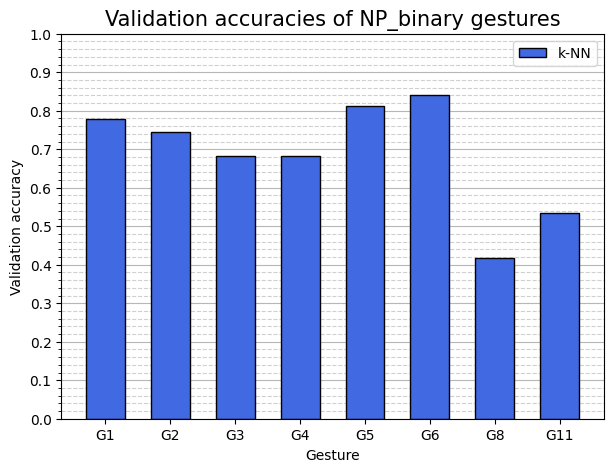

In [56]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_kNN_gestures_ApEn_acc_binary], "Validation accuracies of NP_binary gestures", Needle_Passing_x_axis, "Gesture", \
            np.arange(0, 1.1, 0.1), "Validation accuracy", ["k-NN"], ["royalblue"], 0.6, (7, 5))

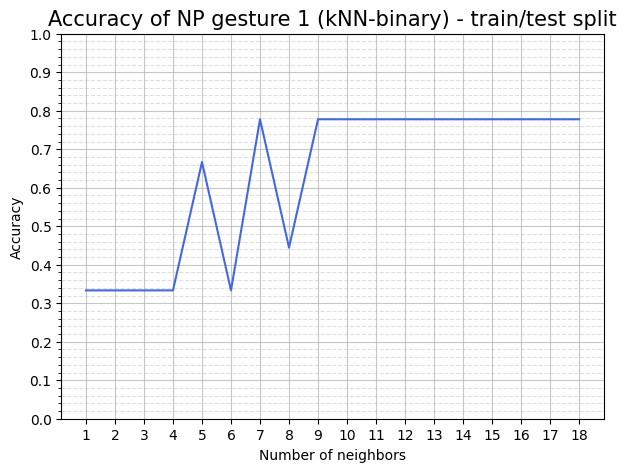

In [57]:
kNN_model_visualization = nts_cam.kNN(1, "distance", "euclidean")
pm.kNN_k_values_plot(kNN_model_visualization, "Accuracy of NP gesture 1 (kNN-binary) - train/test split", "royalblue", "train/test", "accuracy", None, \
                     NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0], (7,5))

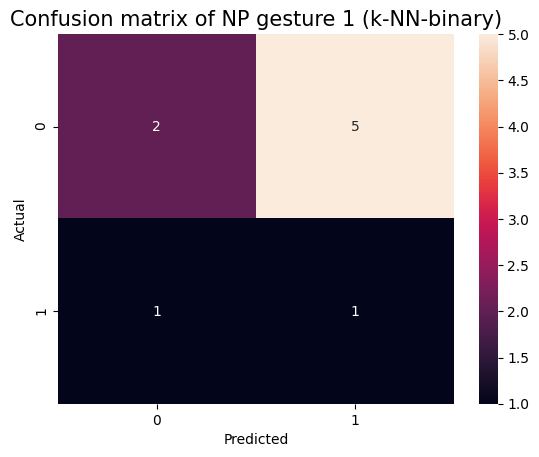

In [58]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of NP gesture 1 (k-NN-binary)", model, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

## 3.4. SVM

### 3.4.1. Model creation and traning-testing

In [59]:
#SVM(C, kernel, gamma, binary_class)
    #binary_class: True, False
        #True: binary classification
        #False: multiclass classification
SVM_model_ApEn_binary = nts_cam.SVM(2.0, "poly", 1.0, True)
SVM_model_ApEn_multi = nts_cam.SVM(2.0, "poly", 1.0, False)
SVM_standardized_model_ApEn_binary = nts_cam.SVM(2.0, "poly", 1.0, True)
SVM_standardized_model_ApEn_multi = nts_cam.SVM(2.0, "poly", 1.0, False)

SVM_model_ApEn_binary

SVC(C=2.0, gamma=1.0, kernel='poly', random_state=0)

In [60]:
#One gesture
#Model_classification_report(model, X_train, X_test, Y_train, Y_test)
vrm.Model_classification_report(SVM_model_ApEn_binary, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

Actual classes: [0 0 0 1 0 0 0 0 1], Predicted classes: [1 0 1 0 1 1 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.67      0.29      0.40         7
           1       0.17      0.50      0.25         2

    accuracy                           0.33         9
   macro avg       0.42      0.39      0.33         9
weighted avg       0.56      0.33      0.37         9



### 3.4.2. Results checking

In [61]:
from sklearn import svm

In [62]:
#Checking the results
model = svm.SVC(C=2.0, gamma=1.0, kernel="poly", random_state=0)
model.fit(NP_gestures_X_train_ApEn[0], NP_gestures_Y_train_ApEn_binary[0])
model.score(NP_gestures_X_test_ApEn[0], NP_gestures_Y_test_ApEn_binary[0])

0.3333333333333333

### 3.4.3. Cross-validation

In [63]:
#All gestures
model_cv = svm.SVC(C=2.0, gamma=1.0, kernel="poly", random_state=0)
NP_SVM_gestures_ApEn_acc_binary = []

for i in range(len(NP_gestures_X_train_ApEn)):
    print(f"Gesture: {Needle_Passing_gestures_binary[i]}")
    NP_SVM_gestures_ApEn_acc_binary.append(vrm.Cross_validation(model_cv, NP_gestures_X_train_ApEn[i], NP_gestures_Y_train_ApEn_binary[i], 3))
    print(f"{NP_SVM_gestures_ApEn_acc_binary[i]}\n")

Gesture: 1
0.7777777777777778

Gesture: 2
0.6904761904761904

Gesture: 3
0.6825396825396824

Gesture: 4
0.5793650793650794

Gesture: 5
0.7444444444444445

Gesture: 6
0.6825396825396824

Gesture: 8
0.48333333333333334

Gesture: 11
0.6555555555555556



### 3.4.4. SVM visualization

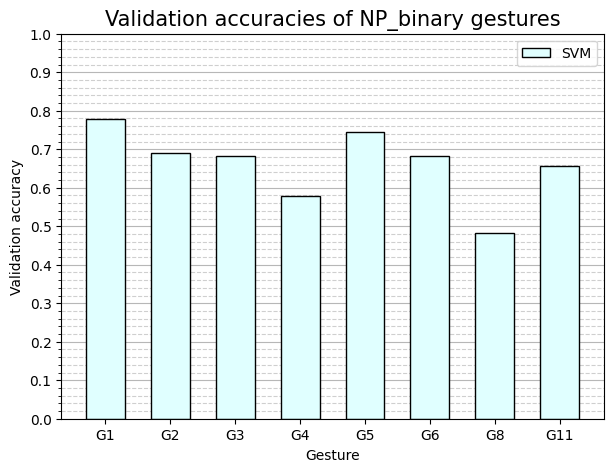

In [64]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_SVM_gestures_ApEn_acc_binary], "Validation accuracies of NP_binary gestures", Needle_Passing_x_axis, "Gesture", \
            np.arange(0, 1.1, 0.1), "Validation accuracy", ["SVM"], ["lightcyan"], 0.6, (7, 5))

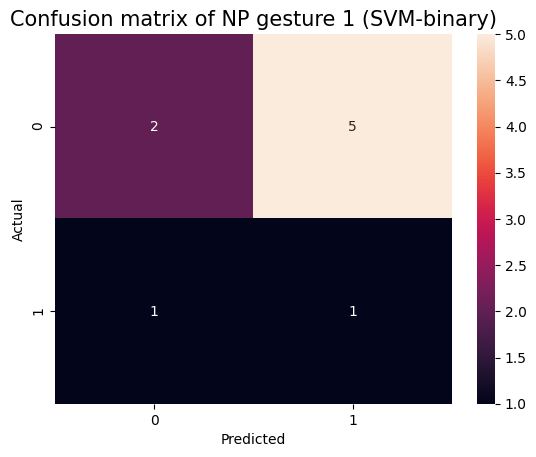

In [65]:
#Confusion_matrix(title, model, X_train, X_test, Y_train, Y_test)
pm.Confusion_matrix("Confusion matrix of NP gesture 1 (SVM-binary)", model, NP_gestures_X_train_ApEn[0], NP_gestures_X_test_ApEn[0], NP_gestures_Y_train_ApEn_binary[0], NP_gestures_Y_test_ApEn_binary[0])

## 3.5. None-time series results plot

In [106]:
NP_DT_gestures_ApEn_acc_binary

[0.6111111111111112,
 0.5158730158730159,
 0.6825396825396824,
 0.6190476190476191,
 0.8666666666666667,
 0.5793650793650793,
 0.5833333333333334,
 0.5333333333333333]

[[0.6111111111111112, 0.5158730158730159, 0.6825396825396824, 0.6190476190476191, 0.8666666666666667, 0.5793650793650793, 0.5833333333333334, 0.5333333333333333], [0.7777777777777778, 0.746031746031746, 0.6825396825396824, 0.6825396825396827, 0.8111111111111112, 0.8412698412698413, 0.4166666666666667, 0.5333333333333333], [0.5555555555555555, 0.6825396825396824, 0.626984126984127, 0.6825396825396824, 0.7555555555555555, 0.7380952380952381, 0.7166666666666667, 0.7111111111111111], [0.7777777777777778, 0.6904761904761904, 0.6825396825396824, 0.5793650793650794, 0.7444444444444445, 0.6825396825396824, 0.48333333333333334, 0.6555555555555556]]
[0 1 2 3 4 5 6 7]


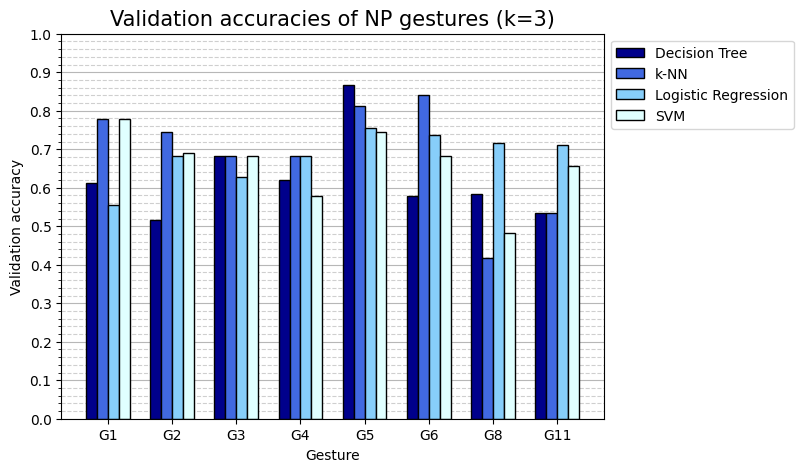

In [107]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_DT_gestures_ApEn_acc_binary, NP_kNN_gestures_ApEn_acc_binary, NP_LR_gestures_ApEn_acc_binary, NP_SVM_gestures_ApEn_acc_binary], "Validation accuracies of NP gestures (k=3)", \
            Needle_Passing_x_axis, "Gesture", np.arange(0, 1.1, 0.1), "Validation accuracy", ["Decision Tree", "k-NN", "Logistic Regression", "SVM"], \
            ["darkblue", "royalblue", "lightskyblue", "lightcyan"], 0.17, (7, 5))

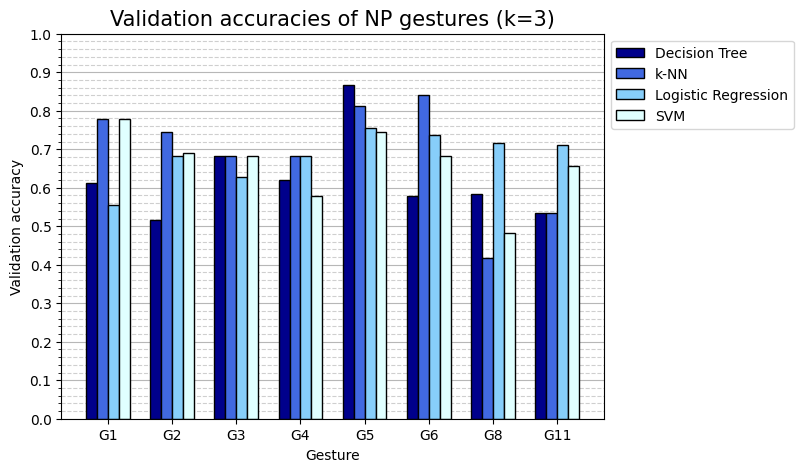

In [66]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([NP_DT_gestures_ApEn_acc_binary, NP_kNN_gestures_ApEn_acc_binary, NP_LR_gestures_ApEn_acc_binary, NP_SVM_gestures_ApEn_acc_binary], "Validation accuracies of NP gestures (k=3)", \
            Needle_Passing_x_axis, "Gesture", np.arange(0, 1.1, 0.1), "Validation accuracy", ["Decision Tree", "k-NN", "Logistic Regression", "SVM"], \
            ["darkblue", "royalblue", "lightskyblue", "lightcyan"], 0.17, (7, 5))

---
## 4. Gestures: Time series classifiers

### 4.1. Time series k-NN with DTW
### 4.1.1. Data transformation

In [19]:
%set_env TF_ENABLE_ONEDNN_OPTS=0
from Modules import ts_classification_algorithms_module as ts_cam

env: TF_ENABLE_ONEDNN_OPTS=0


In [20]:
#[trial][gesture]
NP_gestures[0][0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
165,0.122440,-0.009416,0.369173,0.503405,-0.674849,-0.539635,0.838535,0.532201,0.116587,0.207896,...,-0.197533,0.526692,0.826786,0.008689,0.000199,0.017226,-0.067299,-0.015465,0.040622,-1.199618
166,0.123061,-0.009454,0.370664,0.498900,-0.676487,-0.541765,0.841600,0.527386,0.116381,0.206375,...,-0.196030,0.529450,0.825381,0.008540,-0.004558,0.022066,-0.101243,0.003098,0.025459,-1.203374
167,0.123851,-0.009542,0.372253,0.494349,-0.679900,-0.541665,0.844835,0.522464,0.115140,0.204108,...,-0.193880,0.529689,0.825735,0.009125,0.002773,0.019010,-0.075355,-0.036226,0.069847,-1.203700
168,0.124222,-0.009525,0.373064,0.492112,-0.684211,-0.538263,0.846576,0.520179,0.112669,0.202299,...,-0.192257,0.526462,0.828175,0.009140,0.002962,0.019103,0.025731,0.189645,0.168133,-1.203537
169,0.124820,-0.009403,0.374698,0.487090,-0.698044,-0.524903,0.850600,0.515449,0.103752,0.197538,...,-0.188041,0.513254,0.837382,0.002181,-0.001068,0.024481,0.273337,0.846639,0.382412,-1.205660
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
581,0.124760,0.001993,0.340078,0.403285,0.389159,-0.828228,-0.050361,0.913147,0.404474,0.913200,...,-0.910993,0.147282,0.385226,-0.000404,-0.006240,0.003559,-0.035309,0.016744,-0.018136,-0.272454
582,0.124189,0.001956,0.340122,0.399596,0.383776,-0.832517,-0.048589,0.915752,0.398761,0.914920,...,-0.912750,0.144741,0.382015,-0.013905,0.000905,0.000652,-0.002749,0.033245,-0.065008,-0.271964
583,0.123843,0.001944,0.340163,0.396867,0.379714,-0.835679,-0.047219,0.917674,0.394483,0.916181,...,-0.914075,0.142932,0.379520,-0.014100,-0.004229,0.005149,-0.037357,0.047086,-0.078607,-0.268862
584,0.123098,0.001920,0.340243,0.388461,0.366819,-0.845332,-0.042755,0.923550,0.381050,0.920003,...,-0.917786,0.137994,0.372322,-0.007308,-0.005665,0.003999,0.306264,-1.551509,2.385201,-0.261024


In [21]:
#TS_gestures_df_append_to_max_len(df_list, feature_names)
TS_NP_gestures_df_list_max_len = dmm.TS_gestures_df_append_to_max_len(NP_gestures, feature_names)
TS_NP_gestures_df_list_avg_len = dmm.TS_gestures_df_append_truncate_to_avg_len(NP_gestures, feature_names)
TS_NP_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(NP_gestures)

#TS_gestures_df_append_truncate_to_avg_len(df_list, feature_names)
TS_KT_gestures_df_list_max_len = dmm.TS_gestures_df_append_to_max_len(KT_gestures, feature_names)
TS_KT_gestures_df_list_avg_len = dmm.TS_gestures_df_append_truncate_to_avg_len(KT_gestures, feature_names)
TS_KT_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(KT_gestures)

#TS_gestures_df_truncate_to_min_len(df_list)
TS_SU_gestures_df_list_max_len = dmm.TS_gestures_df_append_to_max_len(SU_gestures, feature_names)
TS_SU_gestures_df_list_avg_len = dmm.TS_gestures_df_append_truncate_to_avg_len(SU_gestures, feature_names)
TS_SU_gestures_df_list_min_len = dmm.TS_gestures_df_truncate_to_min_len(SU_gestures)

In [22]:
TS_NP_gestures_df_list_min_len[0][0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.122440,-0.009416,0.369173,0.503405,-0.674849,-0.539635,0.838535,0.532201,0.116587,0.207896,...,-0.197533,0.526692,0.826786,0.008689,0.000199,0.017226,-0.067299,-0.015465,0.040622,-1.199618
1,0.123061,-0.009454,0.370664,0.498900,-0.676487,-0.541765,0.841600,0.527386,0.116381,0.206375,...,-0.196030,0.529450,0.825381,0.008540,-0.004558,0.022066,-0.101243,0.003098,0.025459,-1.203374
2,0.123851,-0.009542,0.372253,0.494349,-0.679900,-0.541665,0.844835,0.522464,0.115140,0.204108,...,-0.193880,0.529689,0.825735,0.009125,0.002773,0.019010,-0.075355,-0.036226,0.069847,-1.203700
3,0.124222,-0.009525,0.373064,0.492112,-0.684211,-0.538263,0.846576,0.520179,0.112669,0.202299,...,-0.192257,0.526462,0.828175,0.009140,0.002962,0.019103,0.025731,0.189645,0.168133,-1.203537
4,0.124820,-0.009403,0.374698,0.487090,-0.698044,-0.524903,0.850600,0.515449,0.103752,0.197538,...,-0.188041,0.513254,0.837382,0.002181,-0.001068,0.024481,0.273337,0.846639,0.382412,-1.205660
5,0.125391,-0.009287,0.376420,0.481043,-0.709295,-0.515309,0.854029,0.511903,0.092529,0.197567,...,-0.188129,0.499125,0.845860,0.002455,0.004671,0.020186,-0.059688,0.153981,-0.086753,-1.207456
6,0.125637,-0.009250,0.377339,0.476167,-0.714482,-0.512665,0.855662,0.510860,0.082676,0.202244,...,-0.192274,0.493466,0.848245,0.009236,-0.000229,0.024910,1.988645,-1.041430,1.355495,-1.207129
7,0.126072,-0.009376,0.379377,0.471662,-0.717632,-0.512430,0.857003,0.509838,0.074716,0.207058,...,-0.197858,0.489794,0.849089,0.008915,-0.005961,0.029028,-0.162240,0.067639,-0.150981,-1.205823
8,0.126522,-0.009714,0.381642,0.465949,-0.717922,-0.517228,0.858858,0.507491,0.069199,0.212237,...,-0.202799,0.492299,0.846470,0.009081,-0.004898,0.029694,0.516077,-0.477131,0.494916,-1.203700
9,0.126712,-0.010052,0.383903,0.459893,-0.720427,-0.519161,0.861436,0.503805,0.063873,0.214975,...,-0.205771,0.492353,0.845721,0.002004,-0.005811,0.029025,-0.151654,0.011846,-0.001719,-1.205986


In [23]:
#TS_gestures_X_Y_transform(gestures_df, df_class, column_index)
TS_NP_gestures_X_max_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_max_len, NP_class_binary, 2)
TS_KT_gestures_X_max_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_max_len, KT_class_binary, 2)
TS_SU_gestures_X_max_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_max_len, SU_class_binary, 2)

TS_NP_gestures_X_avg_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_avg_len, NP_class_binary, 2)
TS_KT_gestures_X_avg_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_avg_len, KT_class_binary, 2)
TS_SU_gestures_X_avg_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_avg_len, SU_class_binary, 2)

TS_NP_gestures_X_min_len, TS_NP_gestures_Y_binary, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_min_len, NP_class_binary, 2)
TS_KT_gestures_X_min_len, TS_KT_gestures_Y_binary, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_min_len, KT_class_binary, 2)
TS_SU_gestures_X_min_len, TS_SU_gestures_Y_binary, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_min_len, SU_class_binary, 2)

In [24]:
#Multiclass version
TS_NP_gestures_X_max_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_max_len, NP_class_multi, 2)
TS_KT_gestures_X_max_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_max_len, KT_class_multi, 2)
TS_SU_gestures_X_max_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_max_len, SU_class_multi, 2)

TS_NP_gestures_X_avg_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_avg_len, NP_class_multi, 2)
TS_KT_gestures_X_avg_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_avg_len, KT_class_multi, 2)
TS_SU_gestures_X_avg_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_avg_len, SU_class_multi, 2)

TS_NP_gestures_X_min_len, TS_NP_gestures_Y_multi, TS_NP_gestures_valid_gesture_indxs, TS_NP_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_NP_gestures_df_list_min_len, NP_class_multi, 2)
TS_KT_gestures_X_min_len, TS_KT_gestures_Y_multi, TS_KT_gestures_valid_gesture_indxs, TS_KT_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_KT_gestures_df_list_min_len, KT_class_multi, 2)
TS_SU_gestures_X_min_len, TS_SU_gestures_Y_multi, TS_SU_gestures_valid_gesture_indxs, TS_SU_gestures_deleted_trials = dmm.TS_gestures_X_Y_transform(TS_SU_gestures_df_list_min_len, SU_class_multi, 2)

In [25]:
#[gesture][trial]
TS_NP_gestures_X_min_len[0][0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.122440,-0.009416,0.369173,0.503405,-0.674849,-0.539635,0.838535,0.532201,0.116587,0.207896,...,-0.197533,0.526692,0.826786,0.008689,0.000199,0.017226,-0.067299,-0.015465,0.040622,-1.199618
1,0.123061,-0.009454,0.370664,0.498900,-0.676487,-0.541765,0.841600,0.527386,0.116381,0.206375,...,-0.196030,0.529450,0.825381,0.008540,-0.004558,0.022066,-0.101243,0.003098,0.025459,-1.203374
2,0.123851,-0.009542,0.372253,0.494349,-0.679900,-0.541665,0.844835,0.522464,0.115140,0.204108,...,-0.193880,0.529689,0.825735,0.009125,0.002773,0.019010,-0.075355,-0.036226,0.069847,-1.203700
3,0.124222,-0.009525,0.373064,0.492112,-0.684211,-0.538263,0.846576,0.520179,0.112669,0.202299,...,-0.192257,0.526462,0.828175,0.009140,0.002962,0.019103,0.025731,0.189645,0.168133,-1.203537
4,0.124820,-0.009403,0.374698,0.487090,-0.698044,-0.524903,0.850600,0.515449,0.103752,0.197538,...,-0.188041,0.513254,0.837382,0.002181,-0.001068,0.024481,0.273337,0.846639,0.382412,-1.205660
5,0.125391,-0.009287,0.376420,0.481043,-0.709295,-0.515309,0.854029,0.511903,0.092529,0.197567,...,-0.188129,0.499125,0.845860,0.002455,0.004671,0.020186,-0.059688,0.153981,-0.086753,-1.207456
6,0.125637,-0.009250,0.377339,0.476167,-0.714482,-0.512665,0.855662,0.510860,0.082676,0.202244,...,-0.192274,0.493466,0.848245,0.009236,-0.000229,0.024910,1.988645,-1.041430,1.355495,-1.207129
7,0.126072,-0.009376,0.379377,0.471662,-0.717632,-0.512430,0.857003,0.509838,0.074716,0.207058,...,-0.197858,0.489794,0.849089,0.008915,-0.005961,0.029028,-0.162240,0.067639,-0.150981,-1.205823
8,0.126522,-0.009714,0.381642,0.465949,-0.717922,-0.517228,0.858858,0.507491,0.069199,0.212237,...,-0.202799,0.492299,0.846470,0.009081,-0.004898,0.029694,0.516077,-0.477131,0.494916,-1.203700
9,0.126712,-0.010052,0.383903,0.459893,-0.720427,-0.519161,0.861436,0.503805,0.063873,0.214975,...,-0.205771,0.492353,0.845721,0.002004,-0.005811,0.029025,-0.151654,0.011846,-0.001719,-1.205986


### 4.1.2. Train-test split

In [26]:
#Gestures_train_test(X, Y, t_size)
TS_NP_gestures_X_train_max_len, TS_kNN_DTW_NP_gestures_Y_train_max_len_binary, TS_NP_gestures_X_test_max_len, TS_kNN_DTW_NP_gestures_Y_test_max_len_binary = \
        dmm.Gestures_train_test(TS_NP_gestures_X_max_len, TS_NP_gestures_Y_binary, 0.3)
TS_KT_gestures_X_train_max_len, TS_kNN_DTW_KT_gestures_Y_train_max_len_binary, TS_KT_gestures_X_test_max_len, TS_kNN_DTW_KT_gestures_Y_test_max_len_binary = \
        dmm.Gestures_train_test(TS_KT_gestures_X_max_len, TS_KT_gestures_Y_binary, 0.3)
TS_SU_gestures_X_train_max_len, TS_kNN_DTW_SU_gestures_Y_train_max_len_binary, TS_SU_gestures_X_test_max_len, TS_kNN_DTW_SU_gestures_Y_test_max_len_binary = \
        dmm.Gestures_train_test(TS_SU_gestures_X_max_len, TS_SU_gestures_Y_binary, 0.3)

TS_NP_gestures_X_train_avg_len, TS_kNN_DTW_NP_gestures_Y_train_avg_len_binary, TS_NP_gestures_X_test_avg_len, TS_kNN_DTW_NP_gestures_Y_test_avg_len_binary = \
        dmm.Gestures_train_test(TS_NP_gestures_X_avg_len, TS_NP_gestures_Y_binary, 0.3)
TS_KT_gestures_X_train_avg_len, TS_kNN_DTW_KT_gestures_Y_train_avg_len_binary, TS_KT_gestures_X_test_avg_len, TS_kNN_DTW_KT_gestures_Y_test_avg_len_binary = \
        dmm.Gestures_train_test(TS_KT_gestures_X_avg_len, TS_KT_gestures_Y_binary, 0.3)
TS_SU_gestures_X_train_avg_len, TS_kNN_DTW_SU_gestures_Y_train_avg_len_binary, TS_SU_gestures_X_test_avg_len, TS_kNN_DTW_SU_gestures_Y_test_avg_len_binary = \
        dmm.Gestures_train_test(TS_SU_gestures_X_avg_len, TS_SU_gestures_Y_binary, 0.3)

TS_NP_gestures_X_train_min_len, TS_kNN_DTW_NP_gestures_Y_train_min_len_binary, TS_NP_gestures_X_test_min_len, TS_kNN_DTW_NP_gestures_Y_test_min_len_binary = \
        dmm.Gestures_train_test(TS_NP_gestures_X_min_len, TS_NP_gestures_Y_binary, 0.3)
TS_KT_gestures_X_train_min_len, TS_kNN_DTW_KT_gestures_Y_train_min_len_binary, TS_KT_gestures_X_test_min_len, TS_kNN_DTW_KT_gestures_Y_test_min_len_binary = \
        dmm.Gestures_train_test(TS_KT_gestures_X_min_len, TS_KT_gestures_Y_binary, 0.3)
TS_SU_gestures_X_train_min_len, TS_kNN_DTW_SU_gestures_Y_train_min_len_binary, TS_SU_gestures_X_test_min_len, TS_kNN_DTW_SU_gestures_Y_test_min_len_binary = \
        dmm.Gestures_train_test(TS_SU_gestures_X_min_len, TS_SU_gestures_Y_binary, 0.3)

In [27]:
#Multiclass version
TS_NP_gestures_X_train_max_len, TS_kNN_DTW_NP_gestures_Y_train_max_len_multi, TS_NP_gestures_X_test_max_len, TS_kNN_DTW_NP_gestures_Y_test_max_len_multi = \
        dmm.Gestures_train_test(TS_NP_gestures_X_max_len, TS_NP_gestures_Y_multi, 0.3)
TS_KT_gestures_X_train_max_len, TS_kNN_DTW_KT_gestures_Y_train_max_len_multi, TS_KT_gestures_X_test_max_len, TS_kNN_DTW_KT_gestures_Y_test_max_len_multi = \
        dmm.Gestures_train_test(TS_KT_gestures_X_max_len, TS_KT_gestures_Y_multi, 0.3)
TS_SU_gestures_X_train_max_len, TS_kNN_DTW_SU_gestures_Y_train_max_len_multi, TS_SU_gestures_X_test_max_len, TS_kNN_DTW_SU_gestures_Y_test_max_len_multi = \
        dmm.Gestures_train_test(TS_SU_gestures_X_max_len, TS_SU_gestures_Y_multi, 0.3)

TS_NP_gestures_X_train_avg_len, TS_kNN_DTW_NP_gestures_Y_train_avg_len_multi, TS_NP_gestures_X_test_avg_len, TS_kNN_DTW_NP_gestures_Y_test_avg_len_multi = \
        dmm.Gestures_train_test(TS_NP_gestures_X_avg_len, TS_NP_gestures_Y_multi, 0.3)
TS_KT_gestures_X_train_avg_len, TS_kNN_DTW_KT_gestures_Y_train_avg_len_multi, TS_KT_gestures_X_test_avg_len, TS_kNN_DTW_KT_gestures_Y_test_avg_len_multi = \
        dmm.Gestures_train_test(TS_KT_gestures_X_avg_len, TS_KT_gestures_Y_multi, 0.3)
TS_SU_gestures_X_train_avg_len, TS_kNN_DTW_SU_gestures_Y_train_avg_len_multi, TS_SU_gestures_X_test_avg_len, TS_kNN_DTW_SU_gestures_Y_test_avg_len_multi = \
        dmm.Gestures_train_test(TS_SU_gestures_X_avg_len, TS_SU_gestures_Y_multi, 0.3)

TS_NP_gestures_X_train_min_len, TS_kNN_DTW_NP_gestures_Y_train_min_len_multi, TS_NP_gestures_X_test_min_len, TS_kNN_DTW_NP_gestures_Y_test_min_len_multi = \
        dmm.Gestures_train_test(TS_NP_gestures_X_min_len, TS_NP_gestures_Y_multi, 0.3)
TS_KT_gestures_X_train_min_len, TS_kNN_DTW_KT_gestures_Y_train_min_len_multi, TS_KT_gestures_X_test_min_len, TS_kNN_DTW_KT_gestures_Y_test_min_len_multi = \
        dmm.Gestures_train_test(TS_KT_gestures_X_min_len, TS_KT_gestures_Y_multi, 0.3)
TS_SU_gestures_X_train_min_len, TS_kNN_DTW_SU_gestures_Y_train_min_len_multi, TS_SU_gestures_X_test_min_len, TS_kNN_DTW_SU_gestures_Y_test_min_len_multi = \
        dmm.Gestures_train_test(TS_SU_gestures_X_min_len, TS_SU_gestures_Y_multi, 0.3)

In [28]:
TS_NP_gestures_X_train_min_len[0][0]

,Left_MTM_pos_x,Left_MTM_pos_y,Left_MTM_pos_z,Left_MTM_rotM_1,Left_MTM_rotM_2,Left_MTM_rotM_3,Left_MTM_rotM_4,Left_MTM_rotM_5,Left_MTM_rotM_6,Left_MTM_rotM_7,...,PSM2_rotM_7,PSM2_rotM_8,PSM2_rotM_9,PSM2_linV_x,PSM2_linV_y,PSM2_linV_z,PSM2_rotV_alpha,PSM2_rotV_beta,PSM2_rotV_gamma,PSM2_gripper_angleV
0,0.164662,0.021213,0.427073,-0.315160,0.782793,-0.536613,-0.815624,-0.512433,-0.268592,-0.484846,...,-0.542253,0.282863,0.791169,-0.001263,0.010159,-0.030948,0.145423,-0.386363,-0.092995,-0.826922
1,0.164359,0.021750,0.424748,-0.316584,0.777131,-0.543954,-0.813337,-0.517420,-0.265954,-0.487748,...,-0.546124,0.288160,0.786582,-0.001577,0.005639,-0.032880,0.177372,0.000910,0.028238,-0.828719
2,0.164078,0.021806,0.423529,-0.318282,0.773053,-0.548755,-0.811738,-0.521178,-0.263488,-0.489301,...,-0.547926,0.291267,0.784180,-0.007632,-0.000923,-0.028464,0.135264,-0.056203,-0.082482,-0.830841
3,0.163523,0.021744,0.421415,-0.325950,0.763412,-0.557678,-0.810100,-0.529565,-0.251538,-0.486956,...,-0.548013,0.297351,0.781833,-0.007506,-0.004294,-0.022948,0.048981,-0.746569,-0.378811,-0.829535
4,0.162930,0.021660,0.419649,-0.330105,0.754699,-0.567015,-0.806318,-0.537707,-0.246363,-0.490415,...,-0.549661,0.303183,0.778429,-0.007264,-0.000386,-0.021280,0.093616,-0.112993,-0.100597,-0.832638
5,0.162295,0.021641,0.418230,-0.331958,0.750671,-0.571264,-0.806213,-0.540127,-0.241363,-0.489334,...,-0.550063,0.310124,0.775404,-0.006930,-0.001040,-0.014495,0.068120,0.110338,-0.215932,-0.817452
6,0.162042,0.021620,0.417641,-0.335572,0.747557,-0.573232,-0.805163,-0.543425,-0.237433,-0.488594,...,-0.549398,0.311487,0.775330,-0.006872,-0.000113,-0.014089,0.066382,-0.050162,-0.067169,-0.776629
7,0.161797,0.021546,0.416608,-0.340025,0.744056,-0.575161,-0.803312,-0.547737,-0.233766,-0.488556,...,-0.550065,0.311740,0.774755,-0.000766,0.000794,-0.013922,-2.168604,0.798144,-1.388556,-0.712782
8,0.161636,0.021485,0.415780,-0.350632,0.740373,-0.573541,-0.803575,-0.552309,-0.221796,-0.480556,...,-0.542198,0.313066,0.779749,-0.000554,-0.001905,-0.008033,-2.203667,0.878917,-1.588177,-0.615951
9,0.161575,0.021560,0.415440,-0.357870,0.737903,-0.572253,-0.804172,-0.554971,-0.212805,-0.474176,...,-0.535418,0.314921,0.783678,-0.000397,0.005689,-0.011677,-0.145972,0.141359,-0.302218,-0.555533


### 4.1.3. Standardization

In [29]:
#TS_Standardization(X_train, X_test, feature_names)
TS_NP_gestures_standardized_X_train_max_len, TS_NP_gestures_standardized_X_test_max_len = dmm.TS_gesture_standardization(TS_NP_gestures_X_train_max_len, TS_NP_gestures_X_test_max_len, feature_names)
TS_KT_gestures_standardized_X_train_max_len, TS_KT_gestures_standardized_X_test_max_len = dmm.TS_gesture_standardization(TS_KT_gestures_X_train_max_len, TS_KT_gestures_X_test_max_len, feature_names)
TS_SU_gestures_standardized_X_train_max_len, TS_SU_gestures_standardized_X_test_max_len = dmm.TS_gesture_standardization(TS_SU_gestures_X_train_max_len, TS_SU_gestures_X_test_max_len, feature_names)

TS_NP_gestures_standardized_X_train_avg_len, TS_NP_gestures_standardized_X_test_avg_len = dmm.TS_gesture_standardization(TS_NP_gestures_X_train_avg_len, TS_NP_gestures_X_test_avg_len, feature_names)
TS_KT_gestures_standardized_X_train_avg_len, TS_KT_gestures_standardized_X_test_avg_len = dmm.TS_gesture_standardization(TS_KT_gestures_X_train_avg_len, TS_KT_gestures_X_test_avg_len, feature_names)
TS_SU_gestures_standardized_X_train_avg_len, TS_SU_gestures_standardized_X_test_avg_len = dmm.TS_gesture_standardization(TS_SU_gestures_X_train_avg_len, TS_SU_gestures_X_test_avg_len, feature_names)

TS_NP_gestures_standardized_X_train_min_len, TS_NP_gestures_standardized_X_test_min_len = dmm.TS_gesture_standardization(TS_NP_gestures_X_train_min_len, TS_NP_gestures_X_test_min_len, feature_names)
TS_KT_gestures_standardized_X_train_min_len, TS_KT_gestures_standardized_X_test_min_len = dmm.TS_gesture_standardization(TS_KT_gestures_X_train_min_len, TS_KT_gestures_X_test_min_len, feature_names)
TS_SU_gestures_standardized_X_train_min_len, TS_SU_gestures_standardized_X_test_min_len = dmm.TS_gesture_standardization(TS_SU_gestures_X_train_min_len, TS_SU_gestures_X_test_min_len, feature_names)

### 4.1.4. Model creation and traning-testing
| Parameter names | Values                |
|-----------------|-----------------------|
| n_neighbors     | int                   |
| weights         | “uniform”, “distance” |

In [78]:
#Transforming the data into an approppriate format for k-NN DTW
#TS_gesture_kNN_DTW_transform(X_train, X_test)
TS_kNN_DTW_NP_gestures_X_train_max_len, TS_kNN_DTW_NP_gestures_X_test_max_len = dmm.TS_gesture_kNN_DTW_transform(TS_NP_gestures_X_train_max_len, TS_NP_gestures_X_test_max_len)
TS_kNN_DTW_KT_gestures_X_train_max_len, TS_kNN_DTW_KT_gestures_X_test_max_len = dmm.TS_gesture_kNN_DTW_transform(TS_KT_gestures_X_train_max_len, TS_KT_gestures_X_test_max_len)
TS_kNN_DTW_SU_gestures_X_train_max_len, TS_kNN_DTW_SU_gestures_X_test_max_len = dmm.TS_gesture_kNN_DTW_transform(TS_SU_gestures_X_train_max_len, TS_SU_gestures_X_test_max_len)

TS_kNN_DTW_NP_gestures_X_train_avg_len, TS_kNN_DTW_NP_gestures_X_test_avg_len = dmm.TS_gesture_kNN_DTW_transform(TS_NP_gestures_X_train_avg_len, TS_NP_gestures_X_test_avg_len)
TS_kNN_DTW_KT_gestures_X_train_avg_len, TS_kNN_DTW_KT_gestures_X_test_avg_len = dmm.TS_gesture_kNN_DTW_transform(TS_KT_gestures_X_train_avg_len, TS_KT_gestures_X_test_avg_len)
TS_kNN_DTW_SU_gestures_X_train_avg_len, TS_kNN_DTW_SU_gestures_X_test_avg_len = dmm.TS_gesture_kNN_DTW_transform(TS_SU_gestures_X_train_avg_len, TS_SU_gestures_X_test_avg_len)

TS_kNN_DTW_NP_gestures_X_train_min_len, TS_kNN_DTW_NP_gestures_X_test_min_len = dmm.TS_gesture_kNN_DTW_transform(TS_NP_gestures_X_train_min_len, TS_NP_gestures_X_test_min_len)
TS_kNN_DTW_KT_gestures_X_train_min_len, TS_kNN_DTW_KT_gestures_X_test_min_len = dmm.TS_gesture_kNN_DTW_transform(TS_KT_gestures_X_train_min_len, TS_KT_gestures_X_test_min_len)
TS_kNN_DTW_SU_gestures_X_train_min_len, TS_kNN_DTW_SU_gestures_X_test_min_len = dmm.TS_gesture_kNN_DTW_transform(TS_SU_gestures_X_train_min_len, TS_SU_gestures_X_test_min_len)

In [79]:
#Approppriate format for k-NN DTW
TS_kNN_DTW_NP_gestures_X_train_min_len[0].shape

(18, 76, 18)

In [82]:
#Standardized version
TS_kNN_DTW_NP_gestures_standardized_X_train_max_len, TS_kNN_DTW_NP_gestures_standardized_X_test_max_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_NP_gestures_standardized_X_train_max_len, TS_NP_gestures_standardized_X_test_max_len)
TS_kNN_DTW_KT_gestures_standardized_X_train_max_len, TS_kNN_DTW_KT_gestures_standardized_X_test_max_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_KT_gestures_standardized_X_train_max_len, TS_KT_gestures_standardized_X_test_max_len)
TS_kNN_DTW_SU_gestures_standardized_X_train_max_len, TS_kNN_DTW_SU_gestures_standardized_X_test_max_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_SU_gestures_standardized_X_train_max_len, TS_SU_gestures_standardized_X_test_max_len)

TS_kNN_DTW_NP_gestures_standardized_X_train_avg_len, TS_kNN_DTW_NP_gestures_standardized_X_test_avg_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_NP_gestures_standardized_X_train_avg_len, TS_NP_gestures_standardized_X_test_avg_len)
TS_kNN_DTW_KT_gestures_standardized_X_train_avg_len, TS_kNN_DTW_KT_gestures_standardized_X_test_avg_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_KT_gestures_standardized_X_train_avg_len, TS_KT_gestures_standardized_X_test_avg_len)
TS_kNN_DTW_SU_gestures_standardized_X_train_avg_len, TS_kNN_DTW_SU_gestures_standardized_X_test_avg_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_SU_gestures_standardized_X_train_avg_len, TS_SU_gestures_standardized_X_test_avg_len)

TS_kNN_DTW_NP_gestures_standardized_X_train_min_len, TS_kNN_DTW_NP_gestures_standardized_X_test_min_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_NP_gestures_standardized_X_train_min_len, TS_NP_gestures_standardized_X_test_min_len)
TS_kNN_DTW_KT_gestures_standardized_X_train_min_len, TS_kNN_DTW_KT_gestures_standardized_X_test_min_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_KT_gestures_standardized_X_train_min_len, TS_KT_gestures_standardized_X_test_min_len)
TS_kNN_DTW_SU_gestures_standardized_X_train_min_len, TS_kNN_DTW_SU_gestures_standardized_X_test_min_len = \
        dmm.TS_gesture_kNN_DTW_transform(TS_SU_gestures_standardized_X_train_min_len, TS_SU_gestures_standardized_X_test_min_len)

In [83]:
TS_kNN_DTW_model_binary = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_model_multi = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_standardized_model_binary = ts_cam.TS_kNN_DTW(1, "uniform")
TS_kNN_DTW_standardized_model_multi = ts_cam.TS_kNN_DTW(1, "uniform")

TS_kNN_DTW_model_binary

KNeighborsTimeSeriesClassifier()

In [84]:
print("G1 gesture_binary:")
vrm.Model_classification_report(TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_gestures_X_train_min_len[0], TS_kNN_DTW_NP_gestures_X_test_min_len[0], \
                                TS_kNN_DTW_NP_gestures_Y_train_min_len_binary[0], TS_kNN_DTW_NP_gestures_Y_test_min_len_binary[0])

G1 gesture_binary:
Actual classes: [0 0 0 1 0 0 0 0 1], Predicted classes: [1 1 0 0 0 0 1 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.80      0.57      0.67         7
           1       0.25      0.50      0.33         2

    accuracy                           0.56         9
   macro avg       0.53      0.54      0.50         9
weighted avg       0.68      0.56      0.59         9



In [85]:
print("G1 gesture_multi:")
vrm.Model_classification_report(TS_kNN_DTW_model_multi, TS_kNN_DTW_NP_gestures_X_train_min_len[0], TS_kNN_DTW_NP_gestures_X_test_min_len[0], \
                                TS_kNN_DTW_NP_gestures_Y_train_min_len_multi[0], TS_kNN_DTW_NP_gestures_Y_test_min_len_multi[0])

G1 gesture_multi:
Actual classes: [1 1 1 1 0 0 1 1 2], Predicted classes: [1 1 1 1 1 0 2 0 1]

                 Classification Report
-------------------------------------------------------
              precision    recall  f1-score   support

           0       0.50      0.50      0.50         2
           1       0.67      0.67      0.67         6
           2       0.00      0.00      0.00         1

    accuracy                           0.56         9
   macro avg       0.39      0.39      0.39         9
weighted avg       0.56      0.56      0.56         9



### 4.1.5. Results checking

In [86]:
from sktime.classification.distance_based import KNeighborsTimeSeriesClassifier

In [87]:
#Checking the results
print("G1 gesture_binary:")
model = KNeighborsTimeSeriesClassifier(n_neighbors = 1, weights =  "uniform")
model.fit(TS_kNN_DTW_NP_gestures_X_train_min_len[0], TS_kNN_DTW_NP_gestures_Y_train_min_len_binary[0])
model.score(TS_kNN_DTW_NP_gestures_X_test_min_len[0], TS_kNN_DTW_NP_gestures_Y_test_min_len_binary[0])

G1 gesture_binary:


0.5555555555555556

### 4.1.6. Cross-validation

In [88]:
#Calculating the accuracy with cross-validation
#Cross_validation(model, X, Y, cv)
#cv: int, "LOOCV"
print("G1 gesture_binary:")
TS_kNN_DTW_NP_gestures_min_model_cv = vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_gestures_X_train_min_len[0], TS_kNN_DTW_NP_gestures_Y_train_min_len_binary[0], 3)
TS_kNN_DTW_NP_gestures_min_model_cv

G1 gesture_binary:


0.9444444444444445

In [89]:
#All gestures
print("Cross-validation:")
TS_kNN_DTW_NP_gestures_acc_binary = []

for i in range(len(TS_kNN_DTW_NP_gestures_X_train_min_len)):
    print(f"Gesture: {Needle_Passing_gestures[i]}")
    TS_kNN_DTW_NP_gestures_acc_binary.append(vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_NP_gestures_X_train_min_len[i], TS_kNN_DTW_NP_gestures_Y_train_min_len_binary[i], 3))
    print(f"{TS_kNN_DTW_NP_gestures_acc_binary[i]} \n")

Cross-validation:
Gesture: 1
0.9444444444444445 

Gesture: 2
0.746031746031746 

Gesture: 3
0.7936507936507936 

Gesture: 4
0.746031746031746 

Gesture: 5
0.8111111111111112 

Gesture: 6
0.8412698412698413 

Gesture: 8
0.5833333333333334 

Gesture: 11
0.4777777777777777 



In [90]:
#All gestures
print("Cross-validation:")
TS_kNN_DTW_SU_gestures_acc_binary = []

for i in range(len(TS_kNN_DTW_SU_gestures_X_train_min_len)):
    print(f"Gesture: {Suturing_gestures[i]}")
    TS_kNN_DTW_SU_gestures_acc_binary.append(vrm.Cross_validation(TS_kNN_DTW_model_binary, TS_kNN_DTW_SU_gestures_X_train_min_len[i], TS_kNN_DTW_SU_gestures_Y_train_min_len_binary[i], 3))
    print(f"{TS_kNN_DTW_SU_gestures_acc_binary[i]} \n")

Cross-validation:
Gesture: 1
0.6428571428571429 

Gesture: 2
0.8148148148148148 

Gesture: 3
0.7777777777777777 

Gesture: 4
0.7777777777777777 

Gesture: 5
0.7129629629629629 

Gesture: 6
0.7407407407407408 

Gesture: 8
0.6071428571428571 

Gesture: 9
The specified cv value is too big! The maximum value: 2 

Gesture: 10
Y_train contains only a single unique class, which is not suitable for classification. 

Gesture: 11
0.8148148148148149 



### 4.1.7. Time series k-NN visualization

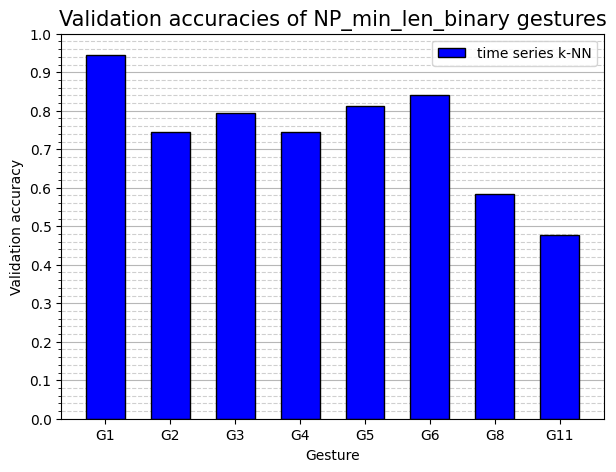

In [91]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([TS_kNN_DTW_NP_gestures_acc_binary], "Validation accuracies of NP_min_len_binary gestures", Needle_Passing_x_axis, "Gesture", \
            np.arange(0, 1.1, 0.1), "Validation accuracy", ["time series k-NN"], ["blue"], 0.6, (7, 5))

In [92]:
Suturing_x_axis = [f"G{i}" for i in Suturing_gestures]
Suturing_x_axis

['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G8', 'G9', 'G10', 'G11']

G10 has no measurable values.
G9 has no measurable values.


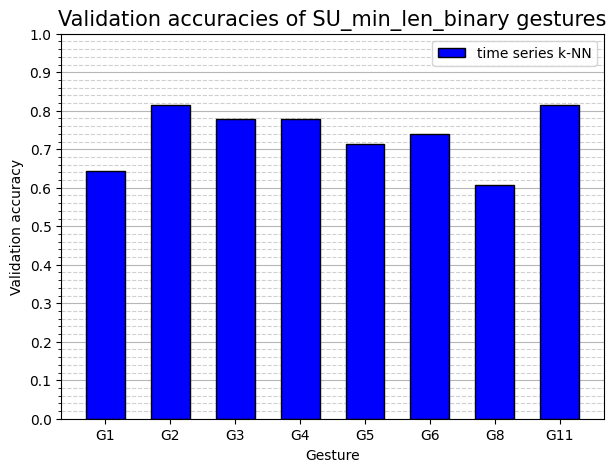

In [93]:
#Bar_plot(accuracies, title, x_axis, x_axis_label, y_axis, y_axis_label, legend_labels, colors, width, fig_size)
pm.Bar_plot([TS_kNN_DTW_SU_gestures_acc_binary], "Validation accuracies of SU_min_len_binary gestures", Suturing_x_axis, "Gesture", \
            np.arange(0, 1.1, 0.1), "Validation accuracy", ["time series k-NN"], ["blue"], 0.6, (7, 5))

---
## 5. Neural Network

In [30]:
#diasble gpu usage, beacuse of an error
from Modules import ts_classification_algorithms_module as ts_cam
import tensorflow as tf
import os
from tensorflow import keras
%set_env TF_ENABLE_ONEDNN_OPTS=0
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

env: TF_ENABLE_ONEDNN_OPTS=0


In [33]:
#Transforming the data into an approppriate format for k-NN DTW
#TS_gesture_kNN_DTW_transform(X_train, X_test)
TS_NN_NP_gestures_X_train_max_len, TS_NN_NP_gestures_X_test_max_len = dmm.TS_gesture_NN_transform(TS_NP_gestures_X_train_max_len, TS_NP_gestures_X_test_max_len)
TS_NN_KT_gestures_X_train_max_len, TS_NN_KT_gestures_X_test_max_len = dmm.TS_gesture_NN_transform(TS_KT_gestures_X_train_max_len, TS_KT_gestures_X_test_max_len)
TS_NN_SU_gestures_X_train_max_len, TS_NN_SU_gestures_X_test_max_len = dmm.TS_gesture_NN_transform(TS_SU_gestures_X_train_max_len, TS_SU_gestures_X_test_max_len)

TS_NN_NP_gestures_X_train_avg_len, TS_NN_NP_gestures_X_test_avg_len = dmm.TS_gesture_NN_transform(TS_NP_gestures_X_train_avg_len, TS_NP_gestures_X_test_avg_len)
TS_NN_KT_gestures_X_train_avg_len, TS_NN_KT_gestures_X_test_avg_len = dmm.TS_gesture_NN_transform(TS_KT_gestures_X_train_avg_len, TS_KT_gestures_X_test_avg_len)
TS_NN_SU_gestures_X_train_avg_len, TS_NN_SU_gestures_X_test_avg_len = dmm.TS_gesture_NN_transform(TS_SU_gestures_X_train_avg_len, TS_SU_gestures_X_test_avg_len)

TS_NN_NP_gestures_X_train_min_len, TS_NN_NP_gestures_X_test_min_len = dmm.TS_gesture_NN_transform(TS_NP_gestures_X_train_min_len, TS_NP_gestures_X_test_min_len)
TS_NN_KT_gestures_X_train_min_len, TS_NN_KT_gestures_X_test_min_len = dmm.TS_gesture_NN_transform(TS_KT_gestures_X_train_min_len, TS_KT_gestures_X_test_min_len)
TS_NN_SU_gestures_X_train_min_len, TS_NN_SU_gestures_X_test_min_len = dmm.TS_gesture_NN_transform(TS_SU_gestures_X_train_min_len, TS_SU_gestures_X_test_min_len)

In [47]:
#Approppriate format for k-NN DTW
TS_NN_NP_gestures_X_train_min_len[0].shape

(18, 18, 76)

In [36]:
#Standardized version
TS_NN_NP_gestures_standardized_X_train_max_len, TS_NN_NP_gestures_standardized_X_test_max_len = dmm.TS_gesture_NN_transform(TS_NP_gestures_standardized_X_train_max_len, TS_NP_gestures_standardized_X_test_max_len)
TS_NN_KT_gestures_standardized_X_train_max_len, TS_NN_KT_gestures_standardized_X_test_max_len = dmm.TS_gesture_NN_transform(TS_KT_gestures_standardized_X_train_max_len, TS_KT_gestures_standardized_X_test_max_len)
TS_NN_SU_gestures_standardized_X_train_max_len, TS_NN_SU_gestures_standardized_X_test_max_len = dmm.TS_gesture_NN_transform(TS_SU_gestures_standardized_X_train_max_len, TS_SU_gestures_standardized_X_test_max_len)

TS_NN_NP_gestures_standardized_X_train_avg_len, TS_NN_NP_gestures_standardized_X_test_avg_len = dmm.TS_gesture_NN_transform(TS_NP_gestures_standardized_X_train_avg_len, TS_NP_gestures_standardized_X_test_avg_len)
TS_NN_KT_gestures_standardized_X_train_avg_len, TS_NN_KT_gestures_standardized_X_test_avg_len = dmm.TS_gesture_NN_transform(TS_KT_gestures_standardized_X_train_avg_len, TS_KT_gestures_standardized_X_test_avg_len)
TS_NN_SU_gestures_standardized_X_train_avg_len, TS_NN_SU_gestures_standardized_X_test_avg_len = dmm.TS_gesture_NN_transform(TS_SU_gestures_standardized_X_train_avg_len, TS_SU_gestures_standardized_X_test_avg_len)

TS_NN_NP_gestures_standardized_X_train_min_len, TS_NN_NP_gestures_standardized_X_test_min_len = dmm.TS_gesture_NN_transform(TS_NP_gestures_standardized_X_train_min_len, TS_NP_gestures_standardized_X_test_min_len)
TS_NN_KT_gestures_standardized_X_train_min_len, TS_NN_KT_gestures_standardized_X_test_min_len = dmm.TS_gesture_NN_transform(TS_KT_gestures_standardized_X_train_min_len, TS_KT_gestures_standardized_X_test_min_len)
TS_NN_SU_gestures_standardized_X_train_min_len, TS_NN_SU_gestures_standardized_X_test_min_len = dmm.TS_gesture_NN_transform(TS_SU_gestures_standardized_X_train_min_len, TS_SU_gestures_standardized_X_test_min_len)

In [ ]:
#TS_NN_model(folder_route, epoch, batch_size, activation_function, drop_out, filters, kernel, num_classes, X_train, Y_train, metric, validation_split)
    # binatry classification: binary_accuracy
    # multi classification: sparse_categorical_accuracy
ts_cam.TS_NN_model("/tf/notebooks/SCARS/NN/test/relu", 100, 10, "relu", 0.2, 16, 3, 2, TS_NN_NP_gestures_X_train_min_len[0], TS_kNN_DTW_NP_gestures_Y_train_min_len_binary[0], "binary_accuracy", 0.3)

Restoring model weights from the end of the best epoch: 56.
Epoch 61: early stopping


In [51]:
#TS_NN_evaluate(folder_route, epoch, X_test, Y_test)
TS_NN_NP_gestures_min_len_loss, TS_NN_NP_gestures_min_len_acc = vrm.TS_NN_evaluate("/tf/notebooks/SCARS/NN/test/relu", 100, TS_NN_NP_gestures_X_test_min_len[0], TS_kNN_DTW_NP_gestures_Y_test_min_len_binary[0])

1/1 [==============================] - 0s 201ms/step - loss: 0.6253 - binary_accuracy: 0.6667


In [52]:
print(TS_NN_NP_gestures_min_len_loss)
print(TS_NN_NP_gestures_min_len_acc)

0.6252971291542053
0.6666666865348816


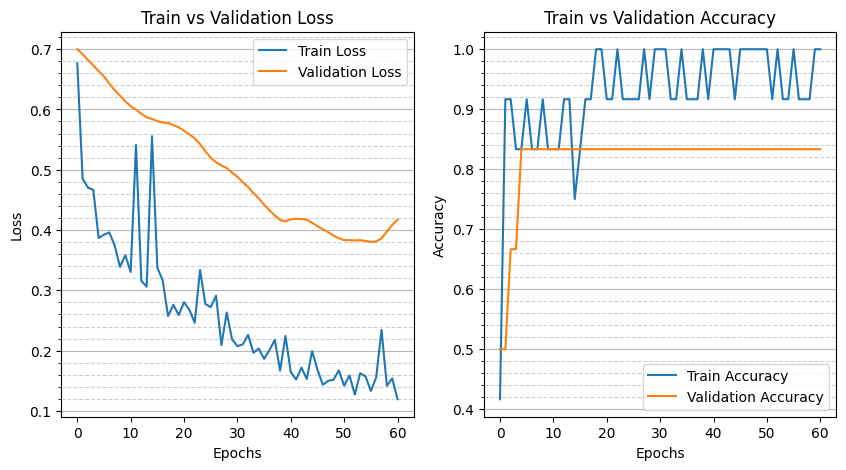

In [55]:
#NN_plot(folder_route, num_class, epoch, fig_size)
pm.NN_plot("/tf/notebooks/SCARS/NN/test/relu", 2, 100, (10, 5))